Next we'll build the Forecasting/ML layer.

The objective is:

Use historical monthly revenue to forecast future revenue.

We'll start with ARIMA because it is interpretable and appropriate for demonstrating time-series forecasting in your portfolio. Later, we can compare it with XGBoost if needed.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA

print("Libraries loaded successfully")

Libraries loaded successfully


Load orders

In [3]:
PROCESSED_PATH = "../data/processed/"

orders = pd.read_csv(
    f"{PROCESSED_PATH}orders_analytics.csv"
)

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

print(orders.shape)

(99441, 22)


Create monthly revenue

In [5]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

monthly_sales = (
    delivered_orders
    .set_index("order_purchase_timestamp")
    .resample("MS")["total_order_value"]
    .sum()
)
#MS means Month Start, so you'll get a proper time-series index:
monthly_sales.head()

order_purchase_timestamp
2016-09-01       143.46
2016-10-01     46490.66
2016-11-01         0.00
2016-12-01        19.62
2017-01-01    127482.37
Freq: MS, Name: total_order_value, dtype: float64

Plot historical revenue

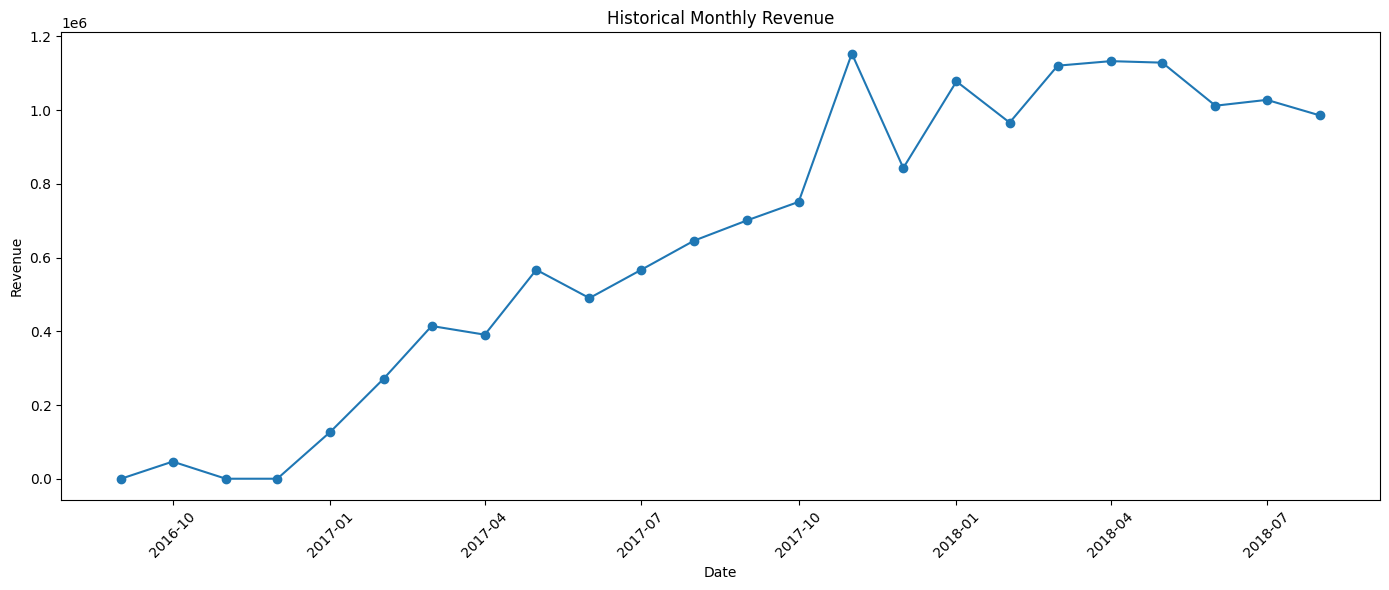

In [6]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Historical Monthly Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Train/Test Split
(keeping the last 6 months as the test set.)

In [7]:
train = monthly_sales.iloc[:-6]
test = monthly_sales.iloc[-6:]

print("Training months:", len(train))
print("Testing months :", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training months: 18
Testing months : 6

Training period:
2016-09-01 00:00:00 to 2018-02-01 00:00:00

Testing period:
2018-03-01 00:00:00 to 2018-08-01 00:00:00


Train ARIMA

In [8]:
model = ARIMA(
    train,
    order=(1, 1, 1)
)

model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:      total_order_value   No. Observations:                   18
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -226.106
Date:                Wed, 16 Sep 2026   AIC                            458.212
Time:                        23:53:09   BIC                            460.711
Sample:                    09-01-2016   HQIC                           458.460
                         - 02-01-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9007      0.591     -1.524      0.128      -2.059       0.258
ma.L1          0.5933      0.674      0.880      0.379      -0.728       1.914
sigma2      2.654e+10   6.69e-11   3.97e+20      0.0

Forecast test period

In [9]:
forecast = model_fit.forecast(
    steps=len(test)
)

forecast.index = test.index

forecast

order_purchase_timestamp
2018-03-01    1.102597e+06
2018-04-01    9.797162e+05
2018-05-01    1.090395e+06
2018-06-01    9.907069e+05
2018-07-01    1.080495e+06
2018-08-01    9.996232e+05
Freq: MS, Name: predicted_mean, dtype: float64

Compare actual vs predicted

In [10]:
comparison = pd.DataFrame({
    "Actual": test,
    "Forecast": forecast
})

comparison

,Actual,Forecast
order_purchase_timestamp,,
2018-03-01,1120598.24,1.102597e+06
2018-04-01,1132878.93,9.797162e+05
2018-05-01,1128774.52,1.090395e+06
2018-06-01,1011978.29,9.907069e+05
2018-07-01,1027807.28,1.080495e+06
2018-08-01,985491.64,9.996232e+05


Calculate forecasting error

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(
    test,
    forecast
)

rmse = np.sqrt(
    mean_squared_error(
        test,
        forecast
    )
)

print(f"MAE  : {mae:,.2f}")
print(f"RMSE : {rmse:,.2f}")

MAE  : 49,605.80
RMSE : 69,142.46


Visualize forecast

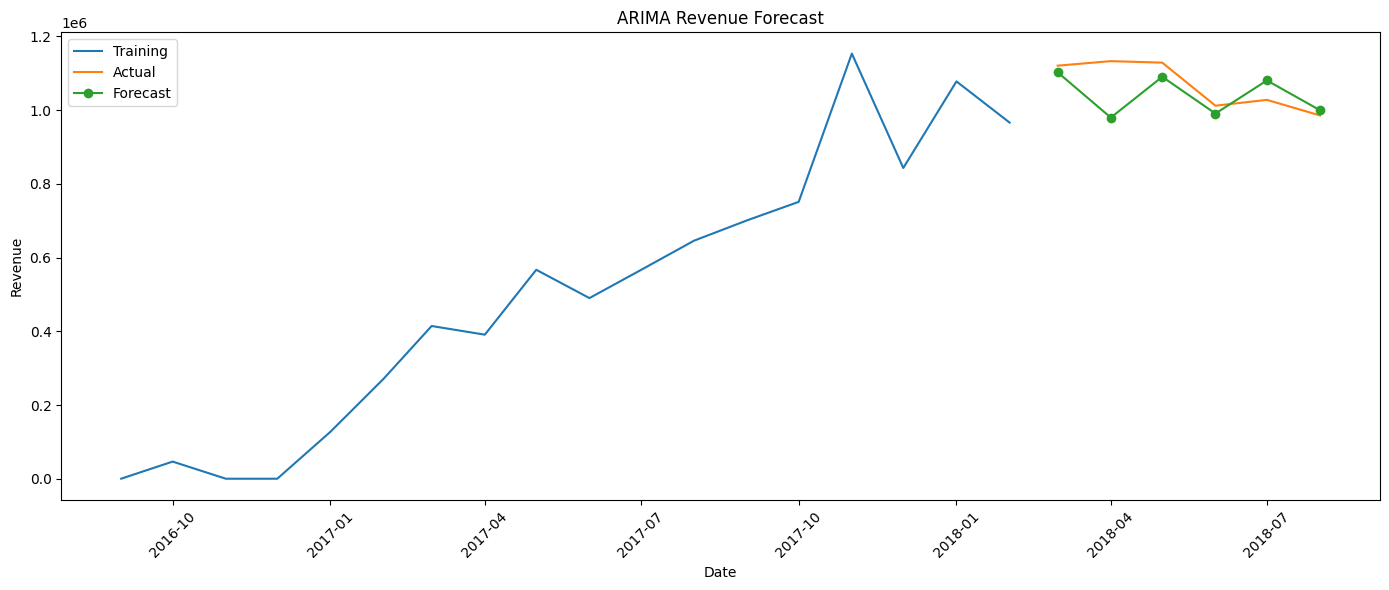

In [12]:
plt.figure(figsize=(14, 6))

plt.plot(
    train.index,
    train.values,
    label="Training"
)

plt.plot(
    test.index,
    test.values,
    label="Actual"
)

plt.plot(
    forecast.index,
    forecast.values,
    marker="o",
    label="Forecast"
)

plt.title("ARIMA Revenue Forecast")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The architecture will be:


User
 │
 │ "What will revenue look like next month?"
 ↓
Forecasting Agent
 │
 ↓
Python Forecasting Tool
 │
 ↓
ARIMA / XGBoost
 │
 ↓
Forecast + Metrics
 │
 ↓
LLM explains the result
 │
 ↓
Business Answer





Python performs the calculation; the AI explains the calculation.

Evaluate the forecast

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(test, forecast)

rmse = np.sqrt(
    mean_squared_error(test, forecast)
)

mape = (
    np.mean(
        np.abs((test - forecast) / test)
    ) * 100
)

print("========== FORECASTING METRICS ==========")
print(f"MAE  : {mae:,.2f}")
print(f"RMSE : {rmse:,.2f}")
print(f"MAPE : {mape:.2f}%")

========== FORECASTING METRICS ==========
MAE  : 49,605.80
RMSE : 69,142.46
MAPE : 4.53%


calculating the percentage error for each month:

In [14]:
comparison["Absolute_Error"] = (
    abs(comparison["Actual"] - comparison["Forecast"])
)

comparison["Percentage_Error"] = (
    comparison["Absolute_Error"]
    / comparison["Actual"]
    * 100
)

comparison

,Actual,Forecast,Absolute_Error,Percentage_Error
order_purchase_timestamp,,,,
2018-03-01,1120598.24,1.102597e+06,18001.207147,1.606393
2018-04-01,1132878.93,9.797162e+05,153162.726553,13.519779
2018-05-01,1128774.52,1.090395e+06,38379.941885,3.400142
2018-06-01,1011978.29,9.907069e+05,21271.374137,2.101960
2018-07-01,1027807.28,1.080495e+06,52687.998179,5.126253
2018-08-01,985491.64,9.996232e+05,14131.544027,1.433959


Compare ARIMA models

In [15]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Different ARIMA configurations
orders = [
    (1, 1, 1),
    (0, 1, 1),
    (1, 1, 0),
    (2, 1, 1)
]

results = []

for order in orders:

    try:
        model = ARIMA(train, order=order)
        model_fit = model.fit()

        forecast = model_fit.forecast(
            steps=len(test)
        )

        mae = mean_absolute_error(
            test,
            forecast
        )

        rmse = np.sqrt(
            mean_squared_error(
                test,
                forecast
            )
        )

        mape = np.mean(
            np.abs(
                (test - forecast) / test
            )
        ) * 100

        results.append({
            "ARIMA": str(order),
            "AIC": model_fit.aic,
            "MAE": mae,
            "RMSE": rmse,
            "MAPE": mape
        })

    except Exception as e:
        print(f"ARIMA{order} failed: {e}")


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="MAE"
).reset_index(drop=True)

results_df

c:\Users\Gyand\OneDrive\Desktop\aiba\venv\lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,ARIMA,AIC,MAE,RMSE,MAPE
0,"(1, 1, 1)",458.211733,49605.798655,69142.463134,4.531414
1,"(1, 1, 0)",456.773162,71595.728299,89753.128585,6.440317
2,"(0, 1, 1)",458.558352,85892.348795,105274.122645,7.741074
3,"(2, 1, 1)",456.831114,146677.854260,190714.774928,14.411041


Select the best model

In [16]:
best_order = eval(
    results_df.iloc[0]["ARIMA"]
)

print("Selected ARIMA model:", best_order)

Selected ARIMA model: (1, 1, 1)


Train the selected model

In [17]:
final_model = ARIMA(
    train,
    order=best_order
)

final_model_fit = final_model.fit()

final_forecast = final_model_fit.forecast(
    steps=len(test)
)

final_forecast.index = test.index

print(final_forecast)

order_purchase_timestamp
2018-03-01    1.102597e+06
2018-04-01    9.797162e+05
2018-05-01    1.090395e+06
2018-06-01    9.907069e+05
2018-07-01    1.080495e+06
2018-08-01    9.996232e+05
Freq: MS, Name: predicted_mean, dtype: float64


Final comparison

In [18]:
final_comparison = pd.DataFrame({
    "Actual": test,
    "Forecast": final_forecast
})

final_comparison["Absolute_Error"] = (
    abs(
        final_comparison["Actual"]
        - final_comparison["Forecast"]
    )
)

final_comparison["Percentage_Error"] = (
    final_comparison["Absolute_Error"]
    / final_comparison["Actual"]
    * 100
)

final_comparison

,Actual,Forecast,Absolute_Error,Percentage_Error
order_purchase_timestamp,,,,
2018-03-01,1120598.24,1.102597e+06,18001.207147,1.606393
2018-04-01,1132878.93,9.797162e+05,153162.726553,13.519779
2018-05-01,1128774.52,1.090395e+06,38379.941885,3.400142
2018-06-01,1011978.29,9.907069e+05,21271.374137,2.101960
2018-07-01,1027807.28,1.080495e+06,52687.998179,5.126253
2018-08-01,985491.64,9.996232e+05,14131.544027,1.433959


Final metrics

In [19]:
final_mae = mean_absolute_error(
    test,
    final_forecast
)

final_rmse = np.sqrt(
    mean_squared_error(
        test,
        final_forecast
    )
)

final_mape = np.mean(
    np.abs(
        (test - final_forecast)
        / test
    )
) * 100

print("========== FINAL MODEL ==========")
print("Model :", best_order)
print(f"MAE   : {final_mae:,.2f}")
print(f"RMSE  : {final_rmse:,.2f}")
print(f"MAPE  : {final_mape:.2f}%")

========== FINAL MODEL ==========
Model : (1, 1, 1)
MAE   : 49,605.80
RMSE  : 69,142.46
MAPE  : 4.53%


                    Monthly Revenue
                          ↓
                     Train / Test
                          ↓
              ┌───────────┼───────────┐
              ↓           ↓           ↓
           (1,1,1)     (0,1,1)     (1,1,0)
              ↓           ↓           ↓
            MAE         MAE         MAE
              └───────────┼───────────┘
                          ↓
                 Model Comparison
                          ↓
                  Selected Model
                          ↓
                  Final Forecast

Generate Future Revenue Forecast

Retrain on all historical data
(Once we've selected (1,1,1), we can train the final model using all available historical observations.)

In [20]:
final_model = ARIMA(
    monthly_sales,
    order=(1, 1, 1)
)

final_model_fit = final_model.fit()

print(final_model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:      total_order_value   No. Observations:                   24
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -303.161
Date:                Thu, 17 Sep 2026   AIC                            612.322
Time:                        00:06:32   BIC                            615.729
Sample:                    09-01-2016   HQIC                           613.179
                         - 08-01-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8042      0.442     -1.820      0.069      -1.670       0.062
ma.L1          0.4837      0.502      0.963      0.335      -0.501       1.468
sigma2      1.957e+10   3.93e-11   4.97e+20      0.0

Forecast next 6 months

In [21]:
future_forecast = final_model_fit.forecast(
    steps=6
)

print("========== NEXT 6 MONTHS FORECAST ==========")
print(future_forecast)

========== NEXT 6 MONTHS FORECAST ==========
2018-09-01    1.012618e+06
2018-10-01    9.908025e+05
2018-11-01    1.008347e+06
2018-12-01    9.942374e+05
2019-01-01    1.005584e+06
2019-02-01    9.964590e+05
Freq: MS, Name: predicted_mean, dtype: float64


Plot historical + future forecast

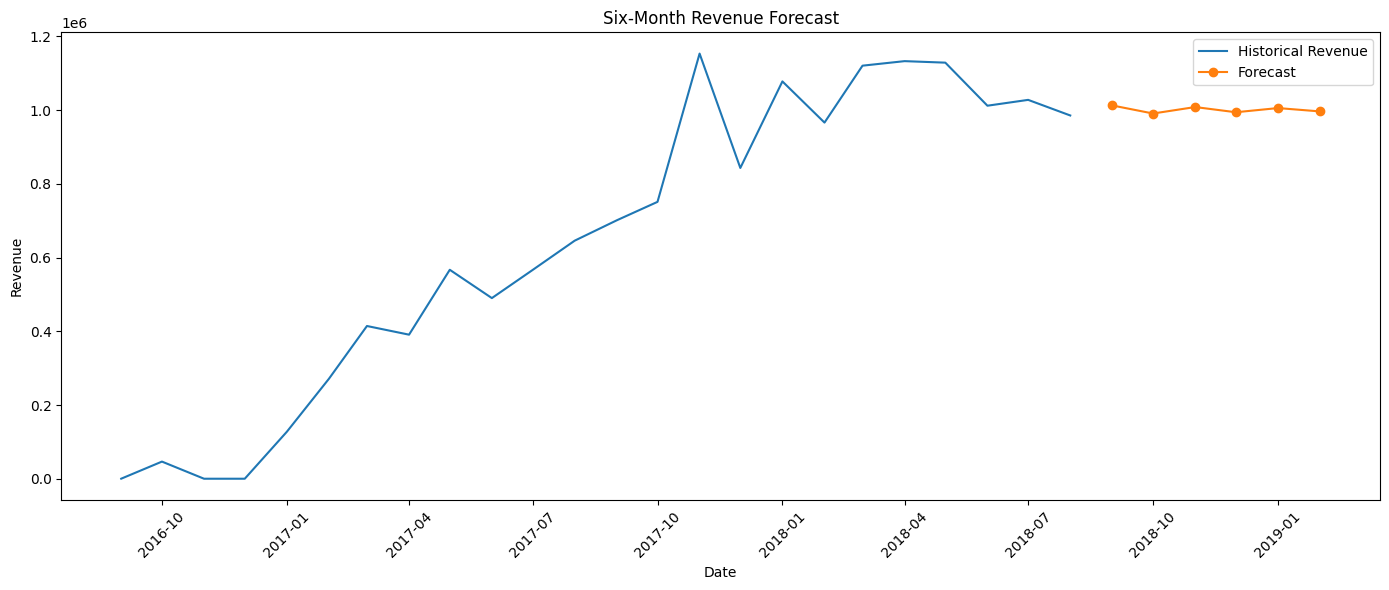

In [22]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    label="Historical Revenue"
)

plt.plot(
    future_forecast.index,
    future_forecast.values,
    marker="o",
    label="Forecast"
)

plt.title("Six-Month Revenue Forecast")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Save forecast

In [23]:
forecast_output = pd.DataFrame({
    "forecast_date": future_forecast.index,
    "forecast_revenue": future_forecast.values
})

forecast_output.to_csv(
    f"{PROCESSED_PATH}revenue_forecast.csv",
    index=False
)

print("Forecast saved successfully.")

Forecast saved successfully.


complete forecasting pipeline  


Olist Orders
     ↓
Monthly Revenue
     ↓
Train/Test Split
     ↓
ARIMA Model Comparison
     ↓
ARIMA(1,1,1)
     ↓
MAE / RMSE / MAPE
     ↓
Retrain on Full Data
     ↓
6-Month Forecast
     ↓
revenue_forecast.csv